# xarray with terrio

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/opengeos/terrio/blob/main/docs/notebooks/xarray.ipynb)

`terrio.xarray` brings [rioxarray](https://corteva.github.io/rioxarray/)'s API to [terrio](https://terrio.dev), without installing GDAL: rasters open lazily as xarray DataArrays with rioxarray's coordinates, attributes and encoding, and the `.terrio` accessor has rioxarray's `.rio` methods (clip, reproject, pad, merge, write). See [xarray](https://terrio.dev/xarray/) in the documentation.

## Install

The `xarray` extra installs xarray and dask; matplotlib is for the plots.

In [1]:
%pip install -q "terrio[xarray]" matplotlib

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

import terrio
import terrio.xarray as txr

plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["figure.dpi"] = 72
terrio.__version__

'0.1.1'

## A cloud-optimized GeoTIFF, opened lazily

A 1 arc-second USGS 3DEP elevation tile (about 50 MB) on Amazon S3. `open_rasterio` reads only its headers: pixels are fetched, tile by tile with HTTP range requests, when they are used. `masked=True` turns nodata into NaN; `chunks=True` makes a dask array with chunks aligned on the file's tiles.

In [3]:
url = "https://prd-tnm.s3.amazonaws.com/StagedProducts/Elevation/1/TIFF/current/n40w106/USGS_1_n40w106.tif"
dem = txr.open_rasterio(url, masked=True, chunks=True)
dem

<xarray.DataArray (band: 1, y: 3612, x: 3612)> Size: 52MB
dask.array<open_rasterio-dbab2e10e6ebf796fa39914e9adff791<this-array>, shape=(1, 3612, 3612), dtype=float32, chunksize=(1, 3612, 3612), chunktype=numpy.ndarray>
Coordinates:
  * band         (band) int64 8B 1
  * y            (y) float64 29kB 40.0 40.0 40.0 40.0 ... 39.0 39.0 39.0 39.0
  * x            (x) float64 29kB -106.0 -106.0 -106.0 ... -105.0 -105.0 -105.0
    spatial_ref  int64 8B 0
Attributes: (12/13)
    BandDefinitionKeyword:     *
    DataType:                  *
    AREA_OR_POINT:             Area
    DESCRIPTION:               *
    LAYER_TYPE:                *
    RepresentationType:        *
    ...                        ...
    STATISTICS_MEAN:           2703.1413711719
    STATISTICS_MINIMUM:        1550.5980224609
    STATISTICS_STDDEV:         553.85086872909
    STATISTICS_VALID_PERCENT:  100
    scale_factor:              1.0
    add_offset:                0.0

Coordinates are pixel centres; the `spatial_ref` coordinate holds the CRS (WKT and CF grid mapping attributes) and the geotransform, as rioxarray writes them, and the nodata value is in the encoding:

In [4]:
print(dem.spatial_ref.attrs["grid_mapping_name"], dem.spatial_ref.attrs["GeoTransform"])
print(dem.encoding["_FillValue"], dem.encoding["dtype"], dem.chunks)
print(dem.terrio.crs, dem.terrio.resolution(), dem.terrio.bounds())

latitude_longitude -106.00166666708242 0.00027777777803598015 0.0 40.00166666698402 0.0 -0.0002777777777870148
-999999.0 float32 ((1,), (3612,), (3612,))
EPSG:4269 (0.00027777777803598015, -0.0002777777777870148) (-106.00166666708242, 38.99833333361733, -104.99833333281647, 40.00166666698402)


## A window, by coordinates

`clip_box` (like `sel`) selects a window: only the tiles under it are fetched when it is computed.

(1, 541, 721)


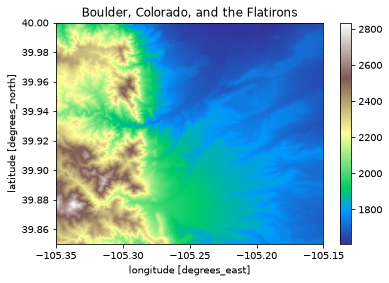

In [5]:
boulder = dem.terrio.clip_box(-105.35, 39.85, -105.15, 40.0, crs="EPSG:4326")
print(boulder.shape)
boulder.squeeze().plot.imshow(cmap="terrain")
plt.title("Boulder, Colorado, and the Flatirons");

## An overview

`overview_level` opens one of the COG's overviews: a quick look at the whole tile.

(1, 451, 451) (0.002224685885290378, -0.002224685883296447)


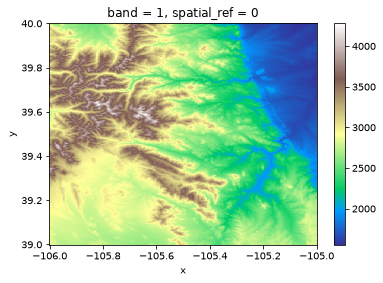

In [6]:
overview = txr.open_rasterio(url, overview_level=2, masked=True)
print(overview.shape, overview.terrio.resolution())
overview.squeeze().plot.imshow(cmap="terrain");

## Reprojecting

`reproject` warps with terrio's implementation of GDAL's warper. `estimate_utm_crs` picks the UTM zone of the data.

EPSG:32613 (1, 558, 572) (30.0, -30.0)


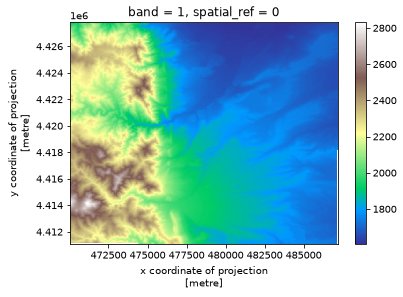

In [7]:
utm_crs = boulder.terrio.estimate_utm_crs()
utm = boulder.terrio.reproject(utm_crs, resolution=30, resampling="bilinear")
print(utm_crs, utm.shape, utm.terrio.resolution())
utm.squeeze().plot.imshow(cmap="terrain");

## Clipping to a polygon

Geometries are GeoJSON-like dicts (or shapely geometries), in the raster's CRS or in `crs`. Pixels outside become NaN (or nodata).

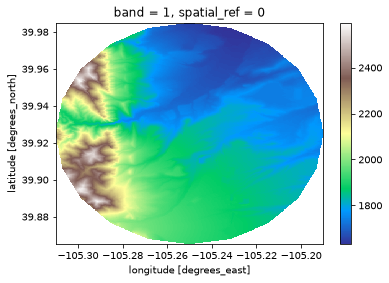

In [8]:
import math

lon0, lat0, r = -105.25, 39.925, 0.06
ring = [(lon0 + r * math.cos(t / 20 * 2 * math.pi), lat0 + r * math.sin(t / 20 * 2 * math.pi)) for t in range(21)]
circle = {"type": "Polygon", "coordinates": [ring]}
clipped = boulder.terrio.clip([circle], crs="EPSG:4326")
clipped.squeeze().plot.imshow(cmap="terrain");

## Merging tiles

`merge_arrays` mosaics arrays (reprojecting those in another CRS or resolution). Here, the overviews of two adjacent 3DEP tiles.

(1, 451, 902) (-107.00166666688256, 38.99833333361733, -104.99500000014926, 40.00166666698402)


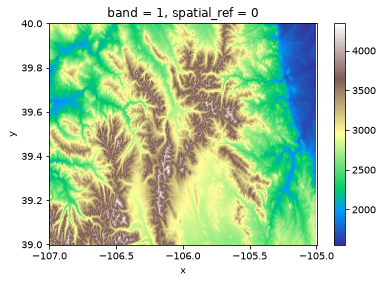

In [9]:
west = "https://prd-tnm.s3.amazonaws.com/StagedProducts/Elevation/1/TIFF/current/n40w107/USGS_1_n40w107.tif"
tiles = [txr.open_rasterio(u, overview_level=2, masked=True) for u in (west, url)]
merged = txr.merge_arrays(tiles)
print(merged.shape, merged.terrio.bounds())
merged.squeeze().plot.imshow(cmap="terrain");

## The xarray backend

`xr.open_dataset(..., engine="terrio")` opens rasters as Datasets, with `mask_and_scale=True` by default as rioxarray's `rasterio` engine (nodata pixels become NaN). A three-band Landsat 7 image, kept as bytes here:

In [10]:
landsat = xr.open_dataset(
    "https://raw.githubusercontent.com/opengeos/data/main/raster/landsat7.tif",
    engine="terrio",
    mask_and_scale=False,
)
landsat

<xarray.Dataset> Size: 13MB
Dimensions:      (band: 3, x: 2181, y: 1917)
Coordinates:
  * band         (band) int64 24B 1 2 3
  * x            (x) float64 17kB -1.365e+07 -1.365e+07 ... -1.359e+07
  * y            (y) float64 15kB 4.576e+06 4.576e+06 ... 4.519e+06 4.519e+06
    spatial_ref  int64 8B ...
Data variables:
    band_data    (band, y, x) uint8 13MB ...

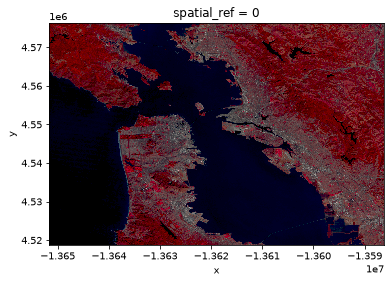

In [11]:
landsat.band_data.plot.imshow(rgb="band");

## Writing

`to_raster` writes GeoTIFFs (`driver="COG"` for cloud-optimized ones), GeoZarr and the other formats terrio writes, with the CRS, transform, nodata, scales, offsets, band descriptions and attributes. Dask arrays are computed chunk by chunk.

In [12]:
utm.terrio.to_raster("boulder_utm.tif", driver="COG", compress="DEFLATE")
utm.terrio.to_raster("boulder_utm.zarr")
back = txr.open_rasterio("boulder_utm.tif", masked=True)
print(back.terrio.crs, back.shape, bool(np.allclose(back.values, utm.values, equal_nan=True)))
print(txr.open_rasterio("boulder_utm.zarr").terrio.crs)

EPSG:32613 (1, 558, 572) True
EPSG:32613


xarray's own `to_zarr` keeps the `spatial_ref` coordinate, so the georeferencing survives: terrio, rioxarray and GDAL read it back.

In [13]:
utm.to_dataset(name="elevation").to_zarr("boulder_xarray.zarr", mode="w", consolidated=False)
z = xr.open_zarr("boulder_xarray.zarr", consolidated=False, decode_coords="all")
print(z.elevation.terrio.crs, z.elevation.terrio.transform() == utm.terrio.transform())
print(terrio.open_raster("boulder_xarray.zarr").crs)

EPSG:32613 True
EPSG:32613


## Code written for rioxarray

`register_rio_accessor()` registers the accessor as `.rio` too (when rioxarray is not imported), so that rioxarray code runs unchanged:

In [14]:
txr.register_rio_accessor()
sub = dem.rio.clip_box(-105.3, 39.9, -105.25, 39.95, crs="EPSG:4326")
print(sub.rio.crs, sub.rio.shape, float(sub.mean()))

EPSG:4269 (181, 181) 1971.7080078125
